## Performance Analysis Based on Close 

In [287]:
import pandas as pd 
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt 

Text(0, 0.5, 'amounts')

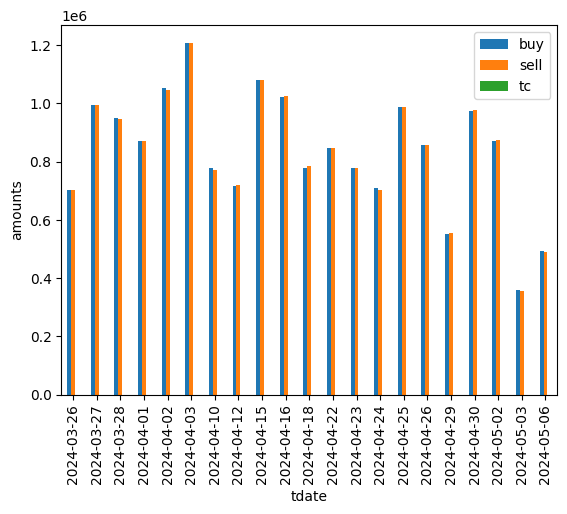

In [288]:
data_output_dir = r'/Users/pankajti/dev/git/wqu/capstone/data/trading_output'
top_performer_count = 25
trades= pd.read_csv(os.path.join(data_output_dir, "trades.csv"))
trades_data= pd.read_csv(os.path.join(data_output_dir, "trades_data.csv"))
daily_return = trades_data.groupby('tdate').sum()[['buy','sell','tc']]
daily_return.plot(kind='bar')
plt.ylabel('amounts')

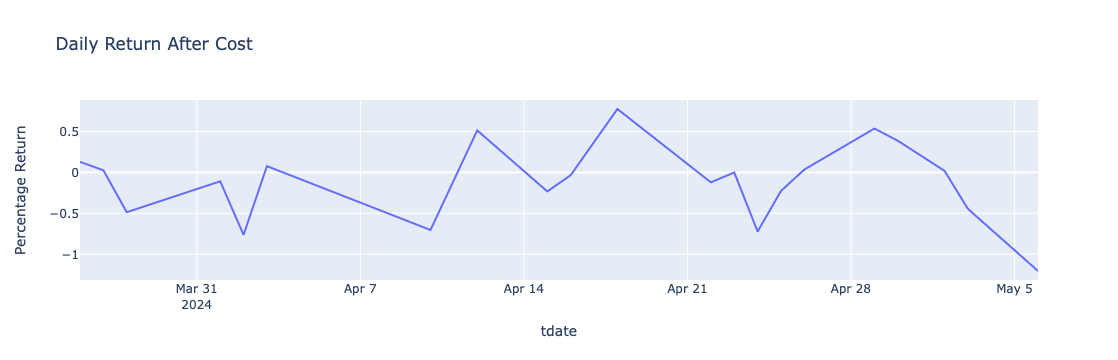

In [289]:
daily_return['per_ret_bc'] = 100*((daily_return.sell-daily_return.buy)/daily_return.buy)
daily_return['per_ret_ac'] = 100*((daily_return.sell-daily_return.buy-daily_return.tc)/daily_return.buy)
fig= px.line(daily_return,daily_return.index, 'per_ret_ac',
             title = "Daily Return After Cost", labels ={"per_ret_ac":"Percentage Return"})
fig.show()

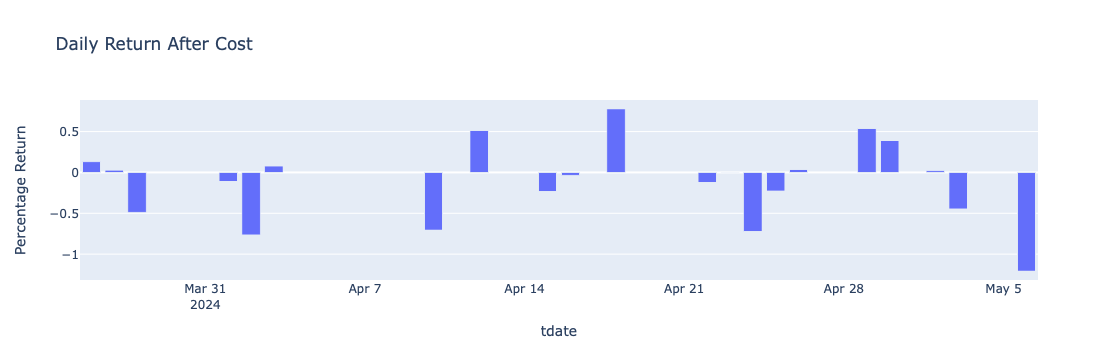

In [290]:
fig= px.bar(daily_return,daily_return.index, 'per_ret_ac',
             title = "Daily Return After Cost", labels ={"per_ret_ac":"Percentage Return"})
fig.show()

In [291]:
cum_ret_bc= (1+daily_return.per_ret_bc/100).cumprod()
cum_ret_bc[-1]

/var/folders/tz/k1k21d6x7j1d90h0t6dqf5yc0000gn/T/ipykernel_6323/627575006.py:2: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



0.9864454977822026

In [292]:
cum_ret_ac= (1+daily_return.per_ret_ac/100).cumprod()
cum_ret_ac[-1]

/var/folders/tz/k1k21d6x7j1d90h0t6dqf5yc0000gn/T/ipykernel_6323/821624623.py:2: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



0.9745781958718608

In [293]:
performance_df = pd.read_csv("over_all_performance.csv")

In [294]:
performance_df = pd.read_csv("simulations/overall_performance_2.csv")

In [295]:
performance_df.head()

,Unnamed: 0,cum_ret_bc,cum_ret_ac,sharpe_ratio_ac,sharpe_ratio_bc,hit_ratio,stop_loss_limit,take_profit_cap,open_interval
0,0,0.156973,0.036611,-0.238541,-0.076247,0.493753,0.0,0.1,10
1,1,0.031189,0.006462,-0.533435,-0.342260,0.493527,0.0,0.1,20
2,2,0.007107,0.000692,-0.498792,-0.330586,0.492924,0.0,0.1,30
3,3,0.010060,0.001896,-0.724992,-0.523826,0.494795,0.0,0.1,40
4,4,0.095285,0.021297,-0.356413,-0.174194,0.500224,0.0,0.1,50


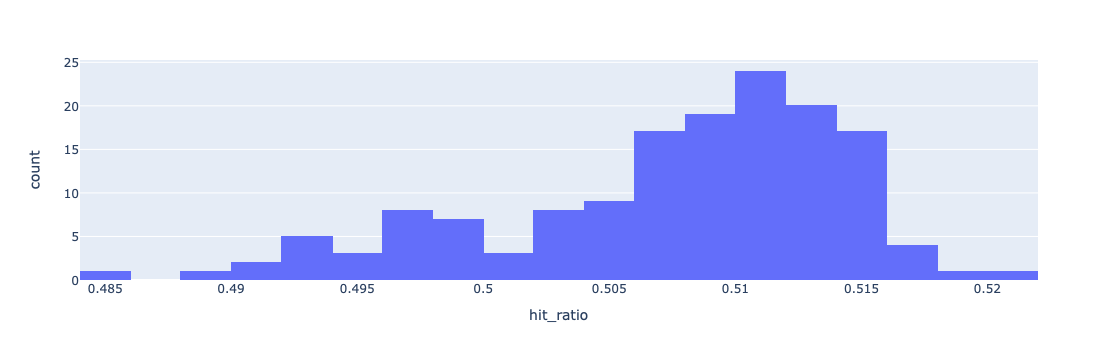

In [296]:
px.histogram(performance_df,'hit_ratio')

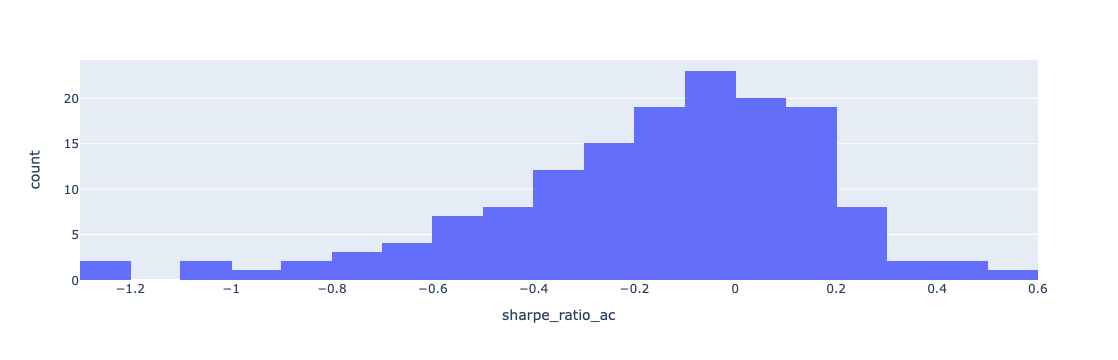

In [328]:
px.histogram(performance_df,'sharpe_ratio_ac')

/Users/pankajti/anaconda3/envs/nlp/lib/python3.11/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning:

divide by zero encountered in log

/Users/pankajti/anaconda3/envs/nlp/lib/python3.11/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning:

invalid value encountered in log



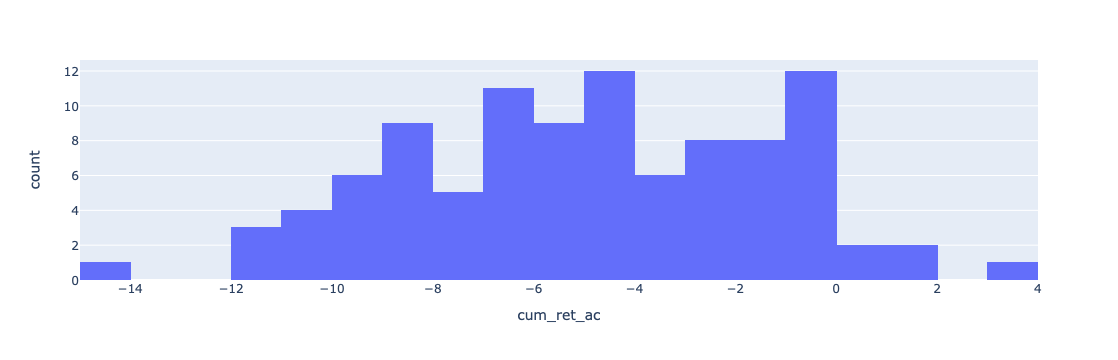

In [329]:
px.histogram(np.log(performance_df),'cum_ret_ac')

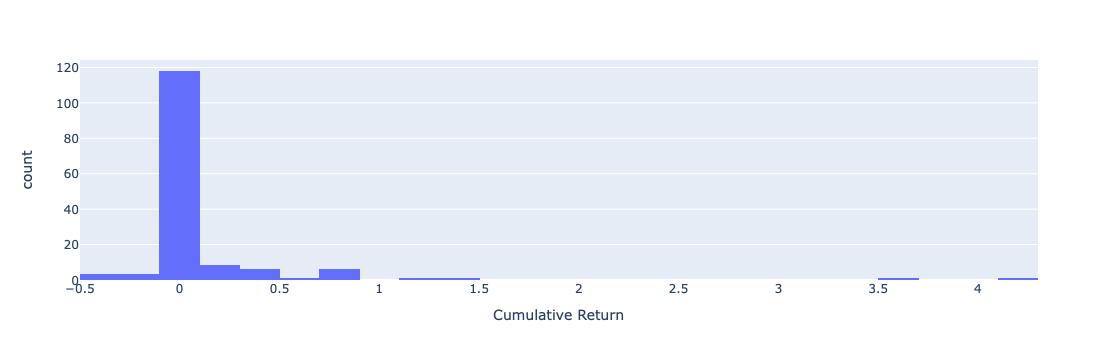

In [319]:
px.histogram(performance_df[performance_df<35],'cum_ret_ac' , labels={'cum_ret_ac':'Cumulative Return '})

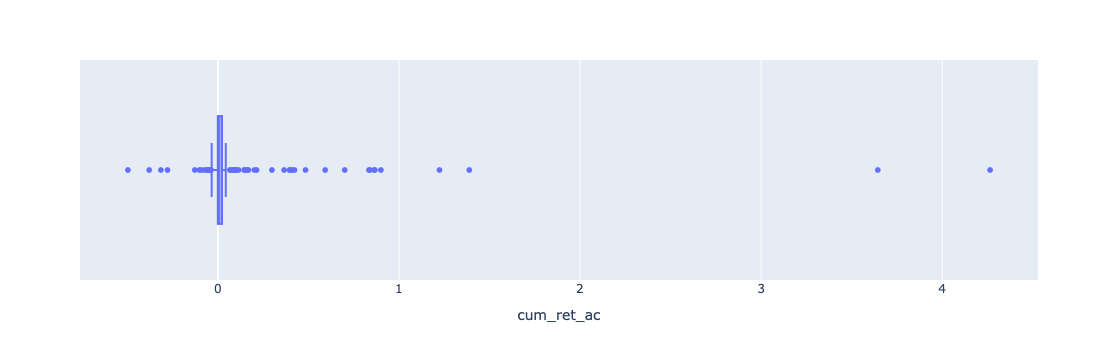

In [316]:
px.box(performance_df[performance_df<35],'cum_ret_ac')

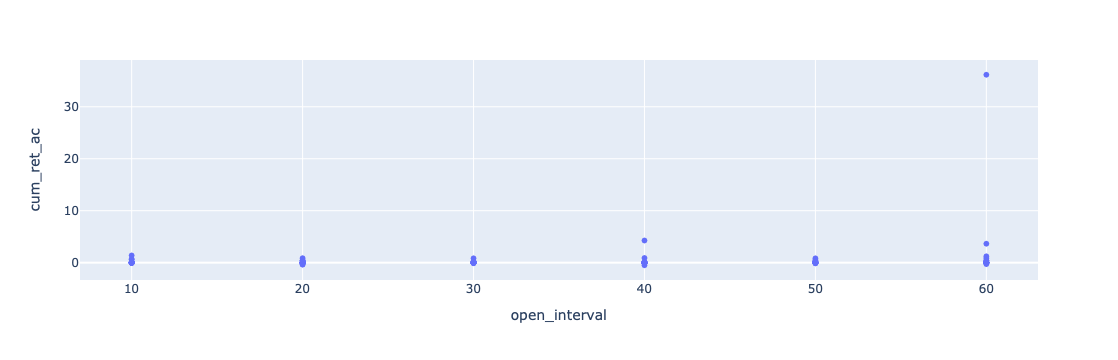

In [299]:
px.scatter(performance_df.sort_values('hit_ratio'),'open_interval','cum_ret_ac') 

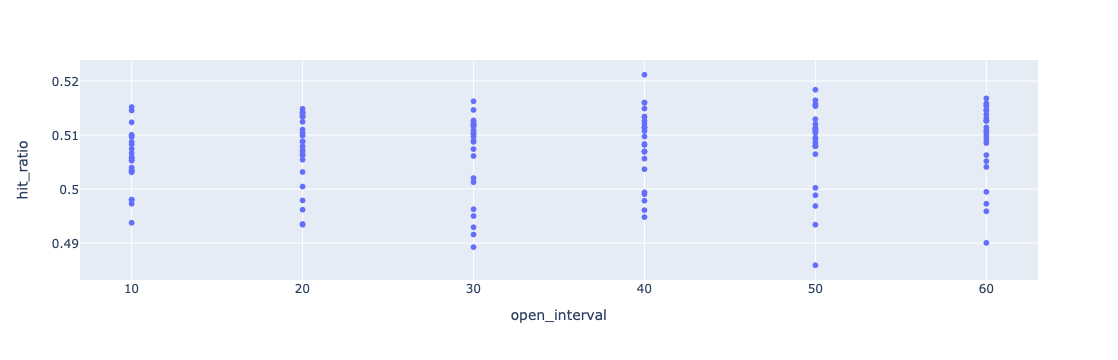

In [300]:
px.scatter(performance_df.sort_values('hit_ratio'),'open_interval','hit_ratio') 

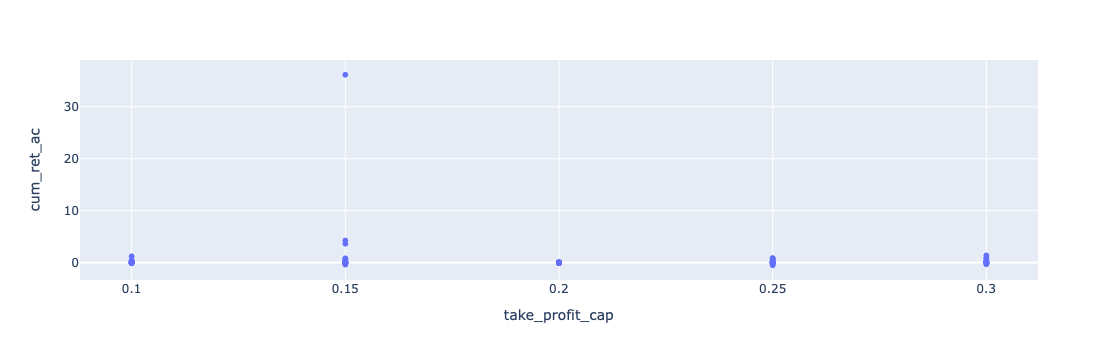

In [301]:
px.scatter(performance_df.sort_values('hit_ratio'),'take_profit_cap','cum_ret_ac') 

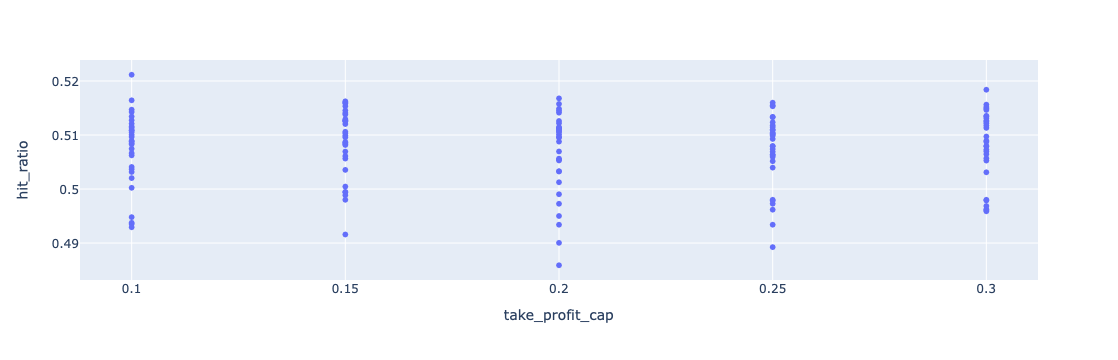

In [302]:
px.scatter(performance_df.sort_values('hit_ratio'),'take_profit_cap','hit_ratio') 

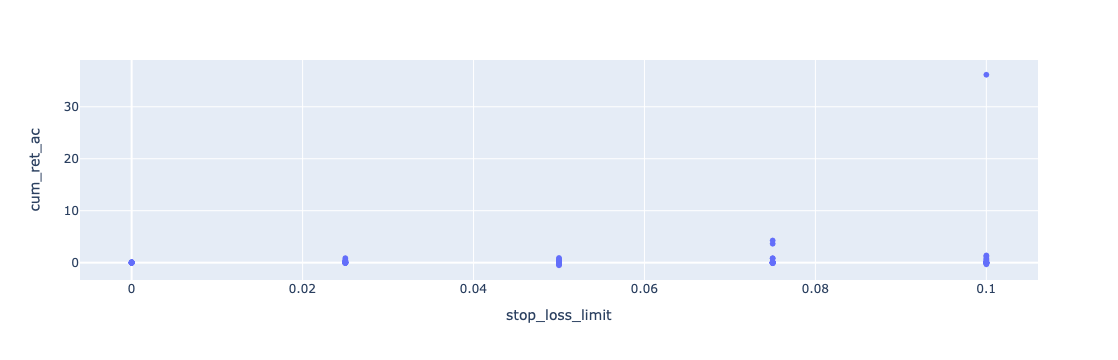

In [303]:
px.scatter(performance_df.sort_values('hit_ratio'),'stop_loss_limit','cum_ret_ac') 

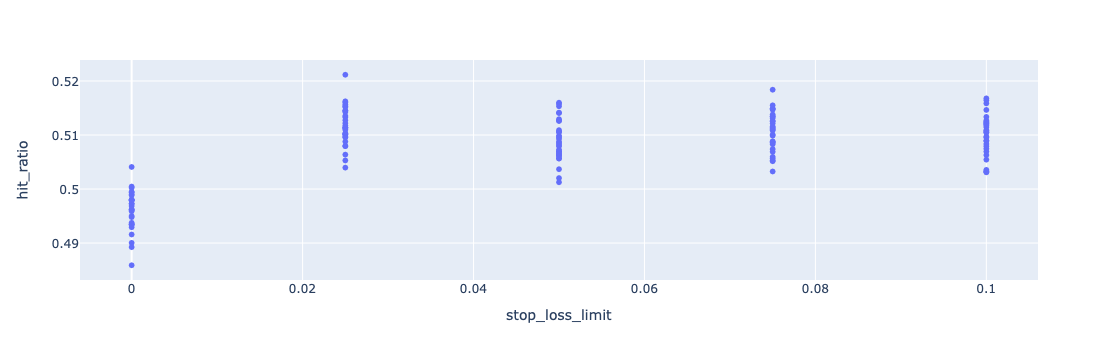

In [304]:
px.scatter(performance_df.sort_values('hit_ratio'),'stop_loss_limit','hit_ratio') 

## Performance Analysis Simulations

In [305]:
simulations_path = r'simulations'

In [306]:
import os 
sim_files = os.listdir(simulations_path)
#sim_files

In [307]:
top_perf_df.columns

Index(['Unnamed: 0', 'cum_ret_bc', 'cum_ret_ac', 'sharpe_ratio_ac',
       'sharpe_ratio_bc', 'hit_ratio', 'stop_loss_limit', 'take_profit_cap',
       'open_interval'],
      dtype='object')

In [308]:
top_perf_dfs = []
all_dfs = []
for sim_file in sim_files:
    df = pd.read_csv(os.path.join(simulations_path,sim_file))
    all_dfs.append(df)
    top_perf_dfs.append(df.sort_values('cum_ret_ac', ascending=False).iloc[:top_performer_count])
top_perf_df= pd.concat(top_perf_dfs)
#top_perf_df.take_profit_cap.hist()


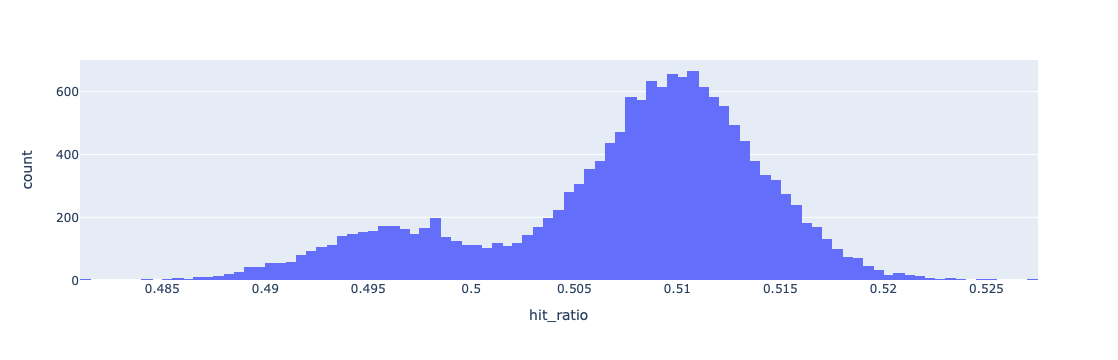

In [309]:
px.histogram(all_df, 'hit_ratio')

In [ ]:
px.histogram(all_df, 'hit_ratio')

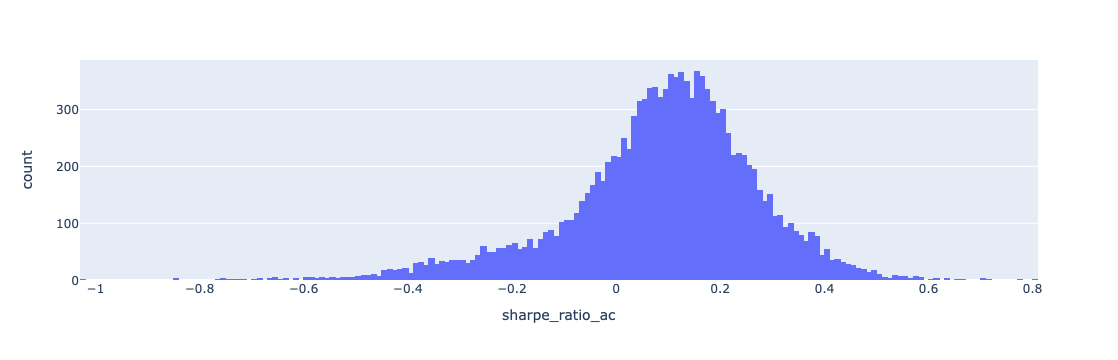

In [331]:
px.histogram(top_perf_df, 'sharpe_ratio_ac')

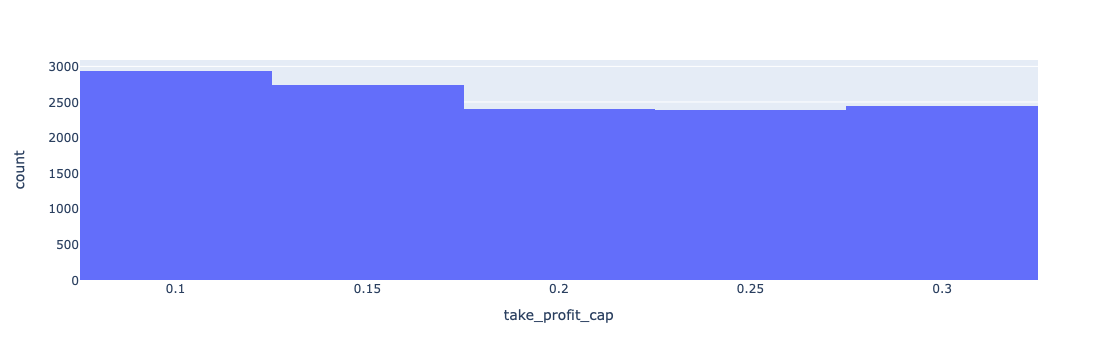

In [311]:
px.histogram(top_perf_df, 'take_profit_cap')

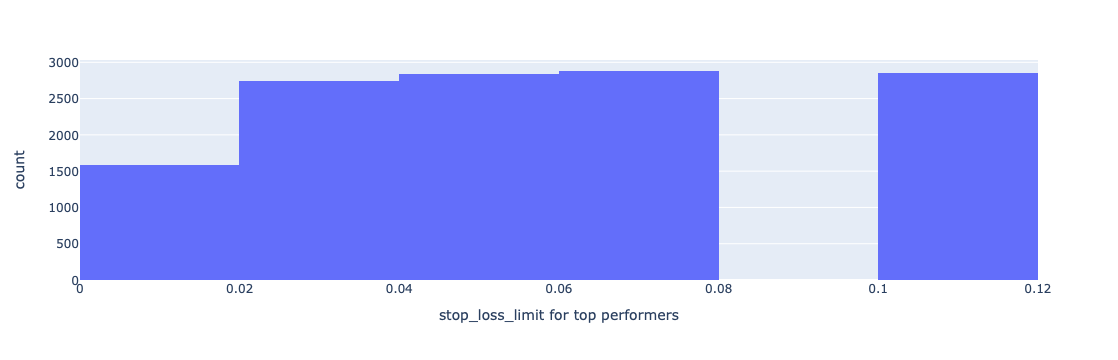

In [330]:
px.histogram(top_perf_df, 'stop_loss_limit' , labels ={'stop_loss_limit' : 'stop_loss_limit for top performers' })

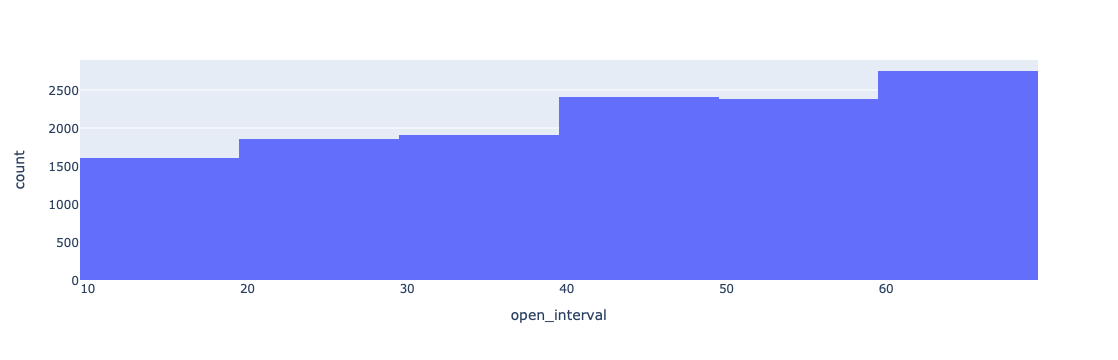

In [313]:
px.histogram(top_perf_df, 'open_interval')

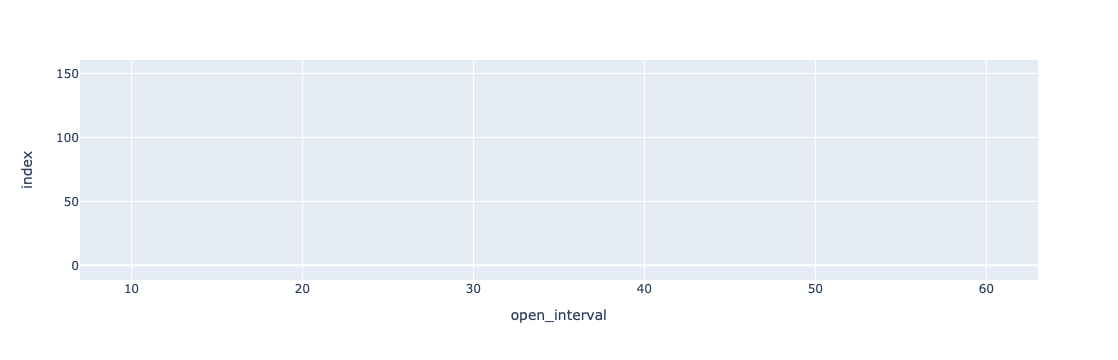

In [326]:
px.scatter(top_perf_df, 'open_interval')

/Users/pankajti/anaconda3/envs/nlp/lib/python3.11/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning:

divide by zero encountered in log

/Users/pankajti/anaconda3/envs/nlp/lib/python3.11/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning:

invalid value encountered in log



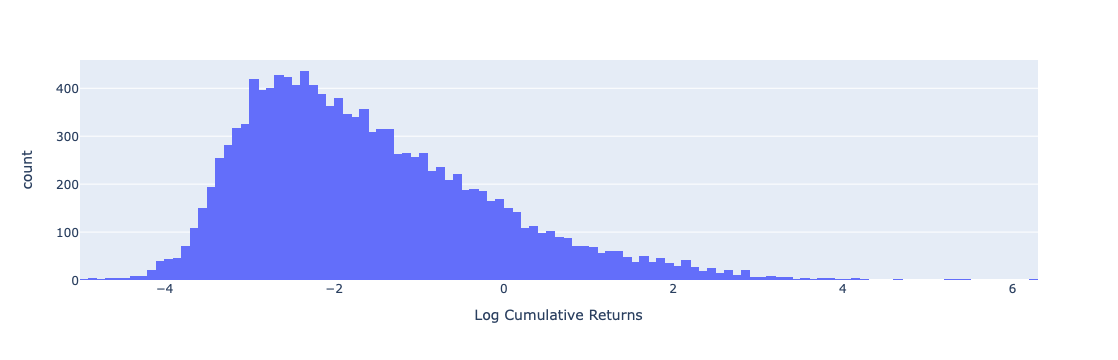

In [325]:
px.histogram(np.log(top_perf_df), 'cum_ret_ac' , labels = {'cum_ret_ac' : 'Log Cumulative Returns'})

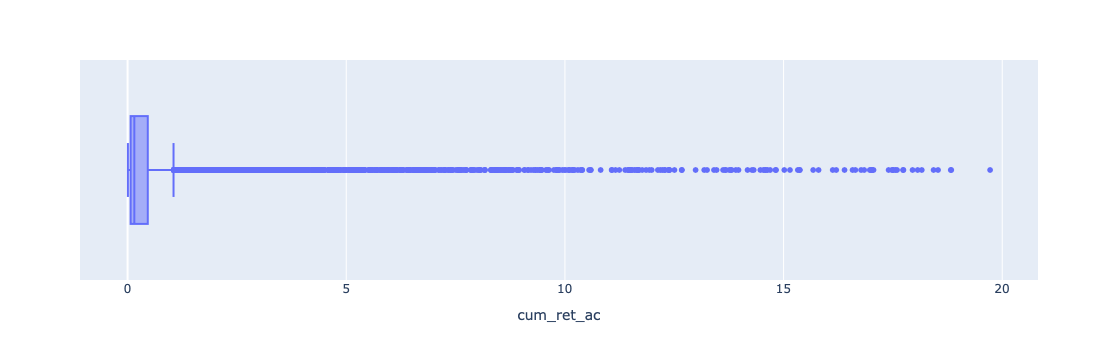

In [322]:
px.box(top_perf_df[top_perf_df<20], 'cum_ret_ac')